# Mission 03 — Part 5: Full Squadron Integration (`ps03_solution.ipynb`)

**Starship Operational Unit:** USSE Noosphere Bridge Crew · **Squadron:** LeCun
**Waypoint:** Pleiades Open Cluster (`SEC-03-M45`) · **Subsystem 03:** Distributed Multi-Head Attention Mesh & KV-Cache Transceiver
**Course:** Conversational AI — Winter Semester 2026/27

This notebook assembles the four station deliverables into one working attention subsystem and checks that they fit together.

| Station | Deliverable | Officer | Used here for |
|---|---|---|---|
| Part 1: Systems Architect | `01_MultiHead_Attention_Core.py` | — | Reference MHSA that the integrated layer must reproduce |
| Part 2: Communications & Protocol Officer | `02_RoPE_Positional_Engine.py` | Vasu Midde | `apply_rope` + `precompute_freqs_cis` inside the layer |
| Part 3: Data & Payload Specialist | `03_GQA_and_KVCache_Benchmark.py` | Sreya Thota | `GQAAttention` (base class), `KVCache`, `kv_cache_bytes` |
| Part 4: Security & Ethics Sentinel | `04_Memory_Hierarchy_and_Safety_Audit.md` | Arjun V R | Tiled online-softmax attention + IO and DoS numbers, re-computed in code |

**Flow of this notebook**
1. Run each station's own verification suite (imported straight from the `.py` files, no copy-paste).
2. Re-derive the Part 4 audit numbers in code (FlashAttention tiling, KV-cache DoS capacity).
3. Build `SquadronAttention` = **GQA (Part 3) + RoPE (Part 2) + KV-cache (Part 3)**, and test it against Parts 1, 3 and PyTorch.
4. Stack it into a tiny decoder (`SquadronLM`), train it on a task that *needs* relative positions, and generate with and without the KV-cache.

Every check uses `assert`, so **"Run All" finishing without an error means every check passed.**

In [1]:
import importlib, math, os, sys, time
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import Image, display

HERE = os.path.abspath("")
sys.path.insert(0, HERE)
# File names start with digits, so they are imported with importlib
p1 = importlib.import_module("01_MultiHead_Attention_Core")
p2 = importlib.import_module("02_RoPE_Positional_Engine")
p3 = importlib.import_module("03_GQA_and_KVCache_Benchmark")

torch.manual_seed(0)
DEVICE = "cpu"  # every check here is small enough for CPU
CHECKS = []     # (station, check) log for the final dashboard
def passed(station, msg):
    CHECKS.append((station, msg)); print(f"[PASS] {msg}")
print("torch", torch.__version__, "| modules loaded:", p1.__name__, p2.__name__, p3.__name__)

torch 2.14.1+cu130 | modules loaded: 01_MultiHead_Attention_Core 02_RoPE_Positional_Engine 03_GQA_and_KVCache_Benchmark


## Station 1 — Systems Architect: Multi-Head Self-Attention

$\text{Attention}(Q,K,V)=\text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}+M\right)V$, with $M=-\infty$ above the diagonal. The variance test shows *why* we divide by $\sqrt{d_k}$: a dot product of $d_k$ unit-variance terms has variance $d_k$; dividing by $\sqrt{d_k}$ brings it back to 1, so softmax doesn't saturate.

=== Subsystem 03: Variance Preservation Empirical Validation ===
Head Dim (d_k =  64):
  * Unscaled Dot Product -> Mean: -0.0020, Var:    63.99 (Expected ~64)
  * Scaled Dot Product   -> Mean: -0.0003, Var:   0.9998 (Expected ~1.0000)
Head Dim (d_k = 128):
  * Unscaled Dot Product -> Mean: +0.0129, Var:   127.90 (Expected ~128)
  * Scaled Dot Product   -> Mean: +0.0011, Var:   0.9992 (Expected ~1.0000)
Head Dim (d_k = 256):
  * Unscaled Dot Product -> Mean: +0.0037, Var:   255.93 (Expected ~256)
  * Scaled Dot Product   -> Mean: +0.0002, Var:   0.9997 (Expected ~1.0000)
[PASS] Variance preservation holds across all head dimensions (Var ~= 1.000).

[PASS] Causal masking strictly preserves past invariant (Past diff: 0.00e+00).
[PASS] Custom MHSA matches PyTorch F.scaled_dot_product_attention (Max diff: 1.79e-07).
[PASS] Output shape (torch.Size([4, 32, 512])) and attention probabilities verified.
[PASS] Part 1 suite: variance 1/sqrt(d_k), causal mask, == PyTorch SDPA, shapes


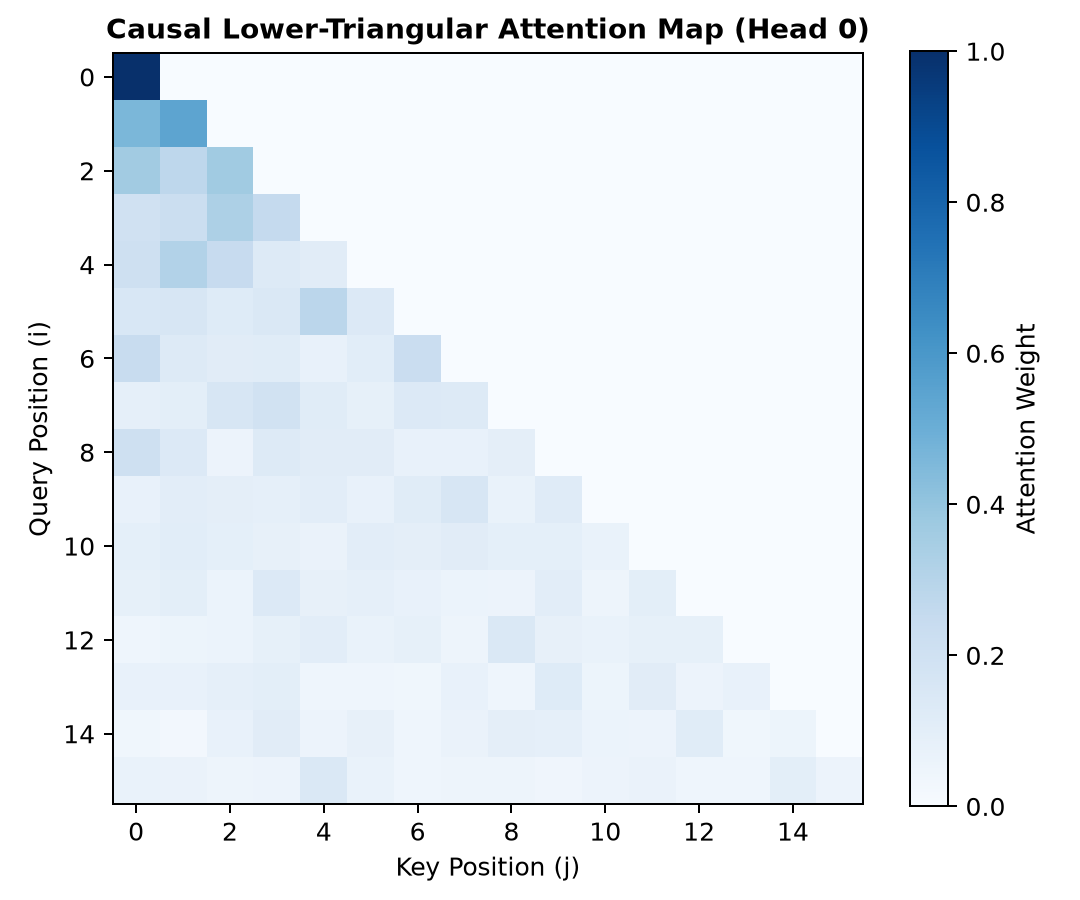

In [2]:
p1.verify_variance_preservation()
p1.test_causal_mask_prevents_future_leakage()
p1.test_equivalence_with_pytorch_reference()
p1.test_tensor_shapes_and_dimensions()
passed("Part 1", "Part 1 suite: variance 1/sqrt(d_k), causal mask, == PyTorch SDPA, shapes")
if os.path.exists("causal_attention_map.png"):
    display(Image("causal_attention_map.png", width=380))

## Station 2 — Communications & Protocol Officer: RoPE

Each pair $(x_{2i},x_{2i+1})$ is a 2D vector turned by angle $m\theta_i$, $\theta_i=10000^{-2(i-1)/d}$. Because both $q$ and $k$ get turned, their dot product only sees the angle *difference*:
$$\langle R_m q, R_n k\rangle=\operatorname{Re}\sum_i q_i\,\overline{k_i}\,e^{i(m-n)\theta_i}=g(q,k,m-n).$$

=== Subsystem 03: RoPE Relative Shift Invariance Verification ===
Dot product <RoPE(q, 10), RoPE(k, 25)>:                 10.773232
Dot product <RoPE(q, 50), RoPE(k, 65)> (delta=40): 10.773234
Absolute Difference: 1.90734863e-06
[PASS] RoPE relative distance invariance holds perfectly across spatial translations!

[PASS] theta_i = 10000^(-2(i-1)/d): theta_1 = 1.000 rad/token, theta_64 = 1.15e-04 rad/token
[PASS] complex e^(i m theta) engine == real 2x2 rotation matrices (max diff 4.2e-06)
[PASS] norm preserved per vector and per 2D pair, position 0 = identity (max norm diff 9.5e-07)
[PASS] shapes/dtypes (fp32, fp16, bf16) preserved, starter API == apply_rope, shape guard works


[PASS] invariance sweep: 200 random (q,k,m,n,delta), |delta| up to 1e5, matches closed form g(q,k,m-n)  (worst diff 3.4e-11)
[PASS] full attention-logit matrix invariant to shifting all positions by 500 (max diff 4.3e-05, float32)

=== Context extrapolation: d=128, train 4,096 -> target 16,384 ===
pair i | theta_i (rad/tok) | wavelength (tok) | max angle train | max angle @target | PI @target
     1 |         1.000e+00 |                6 |        4095.000 |         16383.000 |   4095.750
    16 |         1.155e-01 |               54 |         472.883 |          1891.879 |    472.970
    32 |         1.155e-02 |              544 |          47.288 |           189.188 |     47.297
    47 |         1.334e-03 |            4,712 |           5.461 |            21.847 |      5.462  <- unseen
    48 |         1.155e-03 |            5,441 |           4.729 |            18.919 |      4.730  <- unseen
    64 |         1.155e-04 |           54,410 |           0.473 |             1.892 |      0.473 

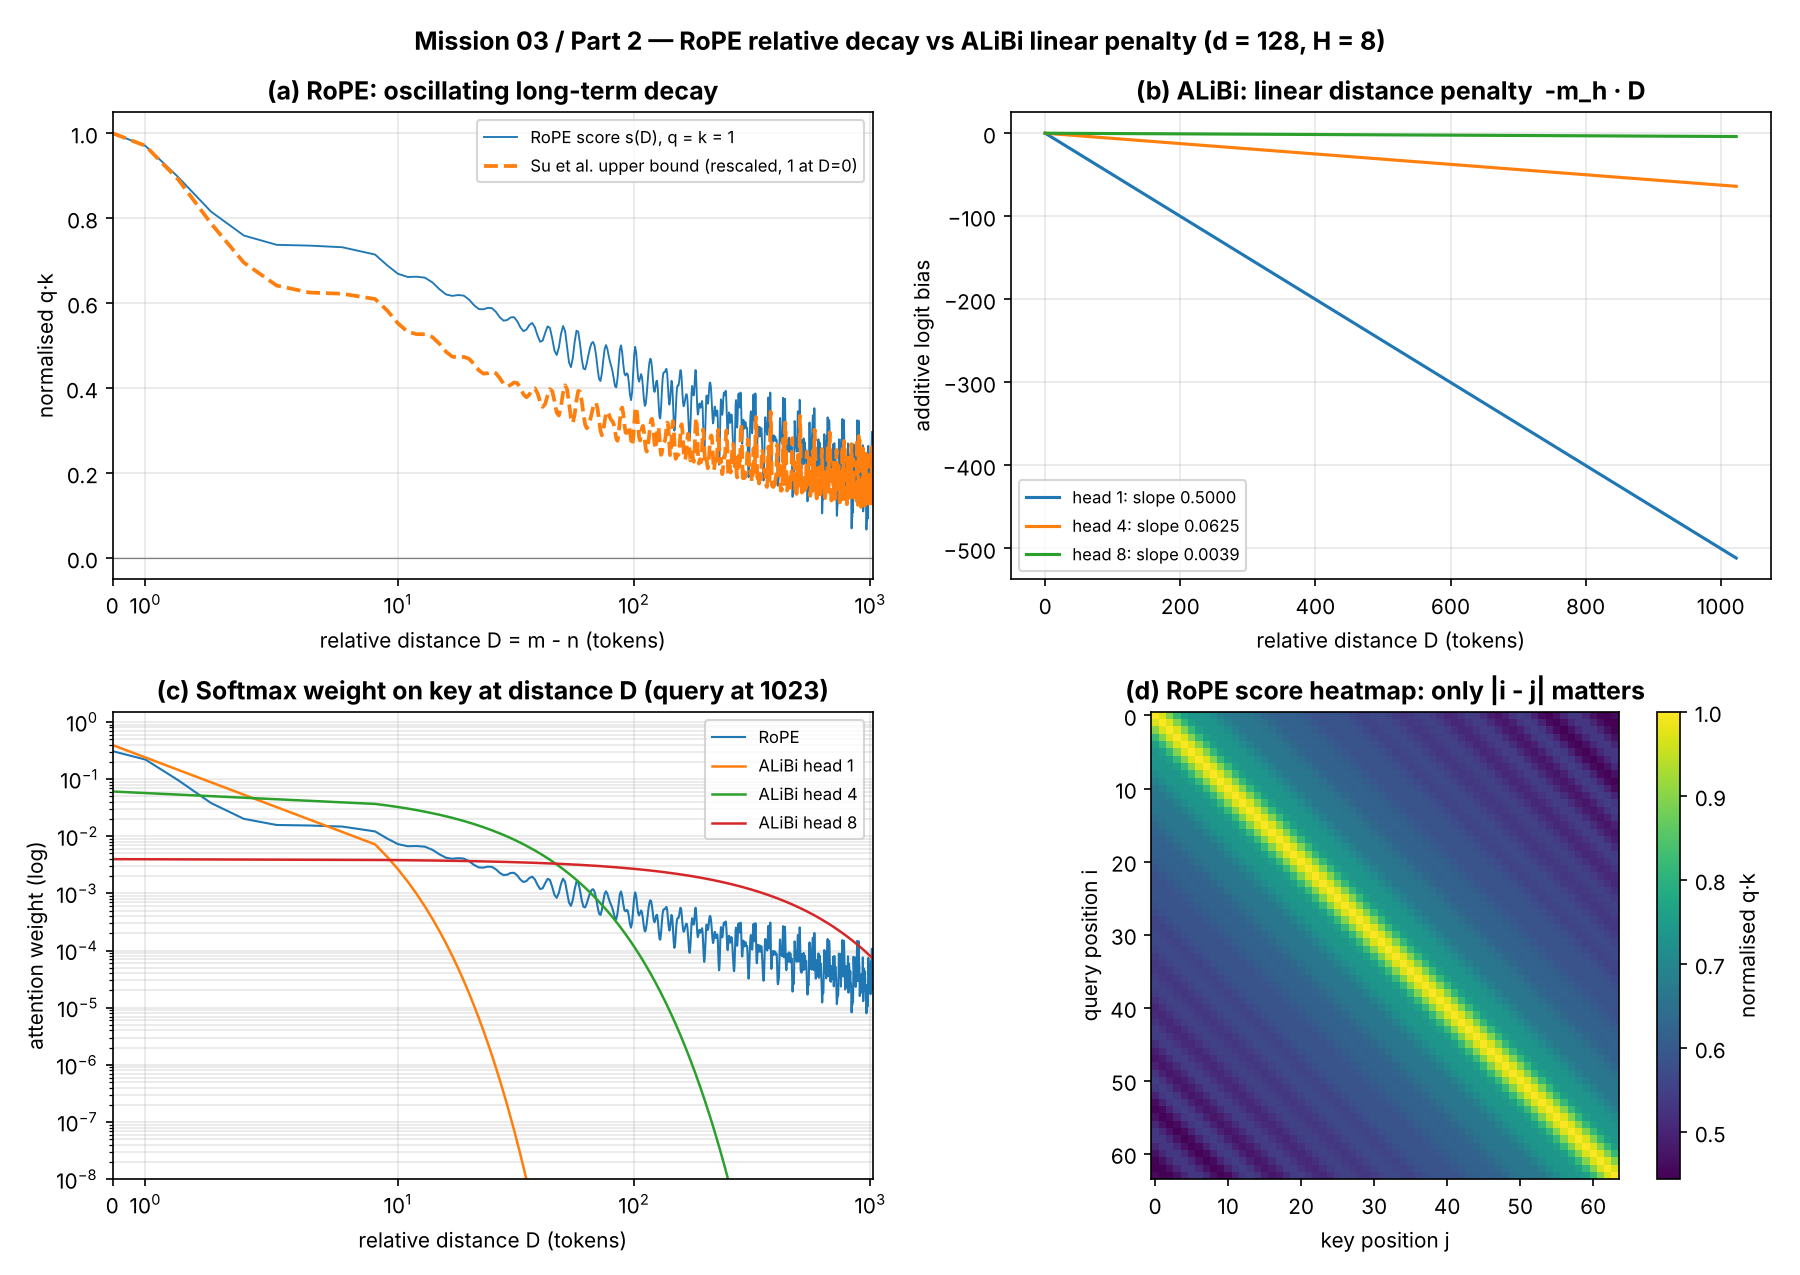

In [3]:
p2.verify_relative_invariance()
p2.test_frequency_formula()
p2.test_complex_matches_real_rotation()
p2.test_norm_and_identity()
p2.test_shapes_dtypes_and_api()
p2.test_relative_invariance_sweep()
p2.test_attention_logits_translation_invariant()
print()
extrap = p2.evaluate_context_extrapolation()
passed("Part 2", "Part 2 suite: theta_i formula, complex == 2x2 rotation, norm, invariance sweep, logit-matrix invariance")
passed("Part 2", f"Extrapolation: {extrap['n_unsafe']}/64 pairs leave trained range beyond 4K; PI repairs all")
if os.path.exists("rope_vs_alibi_decay.png"):
    display(Image("rope_vs_alibi_decay.png", width=820))

## Station 3 — Data & Payload Specialist: GQA + KV-cache

The full latency benchmark lives in the script (`python 03_GQA_and_KVCache_Benchmark.py`). Here we re-run its unit tests and rebuild the memory table from its own formula $2 \times L \times H_{KV} \times d_{head} \times \text{bytes} \times N$.

[PASS] cached decoding == full recompute          (max diff 4.77e-07)
[PASS] GQA == torch scaled_dot_product_attention  (causal)
[PASS] copy-free grouped path == repeat_interleave path
[PASS] causal mask: future tokens cannot change the past
[PASS] head grouping order, cache-size formula, overflow guard
[PASS] Part 3 suite: cache == recompute, == torch, grouped == repeat, causal, head order/formula/overflow

     N |  MHA (MB) | GQA 4:1 (MB) | MQA 32:1 (MB)
  1024 |       512 |          128 |            16
  4096 |     2,048 |          512 |            64
 16384 |     8,192 |        2,048 |           256
 32768 |    16,384 |        4,096 |           512


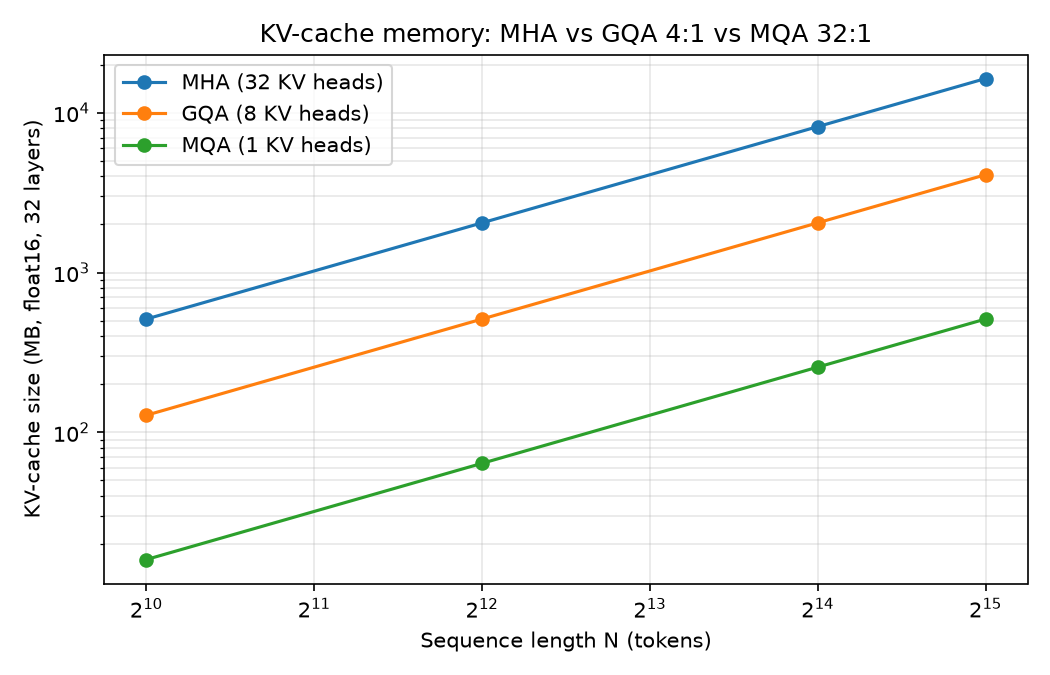

In [4]:
p3.test_cache_matches_full_forward()
p3.test_gqa_matches_torch_reference()
p3.test_copy_free_path_matches_repeat_path()
p3.test_no_peeking_at_future_tokens()
p3.test_head_grouping_and_cache_size()
passed("Part 3", "Part 3 suite: cache == recompute, == torch, grouped == repeat, causal, head order/formula/overflow")

print(f"\n{'N':>6} | {'MHA (MB)':>9} | {'GQA 4:1 (MB)':>12} | {'MQA 32:1 (MB)':>13}")
for n in p3.SEQ_LENGTHS:
    mb = [p3.kv_cache_bytes(n, p3.N_LAYERS, h, p3.HEAD_DIM, p3.BYTES_FP16) / p3.MB for _, h in p3.ARCHS]
    print(f"{n:>6} | {mb[0]:>9,.0f} | {mb[1]:>12,.0f} | {mb[2]:>13,.0f}")
if os.path.exists("kv_cache_memory.png"):
    display(Image("kv_cache_memory.png", width=520))

## Station 4 — Security & Ethics Sentinel: audit numbers, re-computed

The audit (`04_Memory_Hierarchy_and_Safety_Audit.md`) is a written derivation. Here we turn three of its claims into running code:

1. **Tiled online softmax is exact.** FlashAttention never builds the $N\times N$ matrix; it walks over K/V blocks with a running max $m$ and normaliser $\ell$. We implement that loop in plain PyTorch and check it equals standard attention.
2. **IO counts.** We count HBM element reads/writes *inside that loop* and compare with the audit's worked example ($N=8192$, $d=64$, $M\approx 50{,}000$ → about 4× less IO).
3. **DoS capacity table.** We reproduce the 128 KiB/token and "3 sessions at 128K" figures using Part 3's `kv_cache_bytes`.

In [5]:
def flash_attention_tiled(q, k, v, block_c, causal=True, count_io=False):
    '''FlashAttention-style forward for (..., N, d): outer loop over K/V blocks,
    online softmax state (m, l, O) per query row. Never materialises N x N.'''
    *lead, n, d = q.shape
    scale = 1.0 / math.sqrt(d)
    o = torch.zeros_like(q)
    m = torch.full((*lead, n, 1), float("-inf"), dtype=q.dtype)
    l = torch.zeros((*lead, n, 1), dtype=q.dtype)
    io = 0
    rows = torch.arange(n)
    for j0 in range(0, n, block_c):                  # outer loop: K_j, V_j loaded once
        kj, vj = k[..., j0:j0 + block_c, :], v[..., j0:j0 + block_c, :]
        io += 2 * kj.shape[-2] * d                   # read K_j, V_j
        s = (q @ kj.transpose(-2, -1)) * scale       # (.., N, Bc) tile, lives in "SRAM"
        if causal:
            cols = torch.arange(j0, j0 + kj.shape[-2])
            s = s.masked_fill(cols[None, :] > rows[:, None], float("-inf"))
        m_new = torch.maximum(m, s.amax(-1, keepdim=True))
        alpha = torch.exp(m - m_new).nan_to_num(0.0)  # rescale old partial results
        p = torch.exp(s - m_new).nan_to_num(0.0)
        l = alpha * l + p.sum(-1, keepdim=True)
        o = alpha * o + p @ vj
        m = m_new
        io += 3 * n * d                              # read Q, read O, write O (inner loop)
    return (o / l), io

torch.manual_seed(1)
q, k, v = (torch.randn(2, 4, 300, 64, dtype=torch.float64) for _ in range(3))
ref = F.scaled_dot_product_attention(q, k, v, is_causal=True)
for bc in (16, 64, 128):
    out, _ = flash_attention_tiled(q, k, v, bc)
    diff = (out - ref).abs().max().item()
    assert diff < 1e-10, diff
passed("Part 4", f"Tiled online-softmax attention == exact attention for block sizes 16/64/128 (max diff {diff:.1e})")

# Audit worked example: N = 8192, d = 64, M = 50,000 elements of SRAM
N, d, M = 8192, 64, 50_000
Bc = math.ceil(M / (4 * d)); Tc = math.ceil(N / Bc)
io_std = 4 * N * d + 4 * N * N
io_flash_formula = 2 * N * d + 3 * N * d * Tc
# count the same thing by running the loop's bookkeeping on a 1-head toy of size N (no big matmuls needed)
io_flash_loop = sum(2 * min(Bc, N - j0) * d + 3 * N * d for j0 in range(0, N, Bc))
assert io_flash_loop == io_flash_formula
print(f"B_c = {Bc}, T_c = {Tc}")
print(f"standard  IO = 4Nd + 4N^2       = {io_std:.2e} elements")
print(f"flash     IO = 2Nd + 3Nd*T_c    = {io_flash_formula:.2e} elements (loop count agrees)")
print(f"ratio = {io_std / io_flash_formula:.1f}x   |   audit predicts ~4x")
assert 3.5 < io_std / io_flash_formula < 4.5
passed("Part 4", f"IO worked example reproduced: {io_std/io_flash_formula:.1f}x fewer HBM accesses (audit: ~4x)")

[PASS] Tiled online-softmax attention == exact attention for block sizes 16/64/128 (max diff 8.9e-16)
B_c = 196, T_c = 42
standard  IO = 4Nd + 4N^2       = 2.71e+08 elements
flash     IO = 2Nd + 3Nd*T_c    = 6.71e+07 elements (loop count agrees)
ratio = 4.0x   |   audit predicts ~4x
[PASS] IO worked example reproduced: 4.0x fewer HBM accesses (audit: ~4x)


In [6]:
# KV-cache DoS capacity model (audit section 2) using Part 3's own formula
L, H_KV, D_HEAD, BYTES, POOL_GIB = 32, 8, 128, 2, 48
per_tok = p3.kv_cache_bytes(1, L, H_KV, D_HEAD, BYTES)
assert per_tok == 128 * 1024
print(f"KV per token (LLaMA-3-8B-like, GQA 8 KV heads, fp16): {per_tok // 1024} KiB")
print(f"{'context':>8} | {'GQA GiB/session':>15} | {'fits in 48 GiB':>14} | {'MHA GiB/session':>15} | {'fits':>4}")
fits = {}
for ctx in (8_192, 32_768, 131_072):
    g = p3.kv_cache_bytes(ctx, L, H_KV, D_HEAD, BYTES) / 2**30
    m_ = p3.kv_cache_bytes(ctx, L, 32, D_HEAD, BYTES) / 2**30
    fits[ctx] = int(POOL_GIB // g)
    print(f"{ctx:>8} | {g:>15.0f} | {fits[ctx]:>14} | {m_:>15.0f} | {int(POOL_GIB // m_):>4}")
assert fits == {8192: 48, 32768: 12, 131072: 3}

# MLA vs MHA per-token cache, DeepSeek-V3 config quoted in the audit
mha_elems = 2 * 128 * 128 * 61; mla_elems = (512 + 64) * 61
print(f"\nDeepSeek-V3 per token: MHA {mha_elems*2/2**20:.1f} MiB vs MLA {mla_elems*2/2**10:.0f} KiB "
      f"-> {mha_elems/mla_elems:.0f}x smaller")
passed("Part 4", "DoS table reproduced: 128 KiB/token, 48 / 12 / 3 sessions at 8K / 32K / 128K; MLA ~57x vs MHA")

KV per token (LLaMA-3-8B-like, GQA 8 KV heads, fp16): 128 KiB
 context | GQA GiB/session | fits in 48 GiB | MHA GiB/session | fits
    8192 |               1 |             48 |               4 |   12
   32768 |               4 |             12 |              16 |    3
  131072 |              16 |              3 |              64 |    0

DeepSeek-V3 per token: MHA 3.8 MiB vs MLA 69 KiB -> 57x smaller
[PASS] DoS table reproduced: 128 KiB/token, 48 / 12 / 3 sessions at 8K / 32K / 128K; MLA ~57x vs MHA


## Integration — `SquadronAttention` = GQA + RoPE + KV-cache

`SquadronAttention` **inherits** Sreya's `GQAAttention` (same weights `w_q, w_k, w_v, w_o`, same two head-matching paths) and adds Vasu's RoPE between projection and attention. Only three lines are new compared with the Part 3 forward (marked `# <- RoPE`).

**The integration trap.** With a KV-cache, the new token's position is *not* 0 — it is the number of tokens already in the cache. If you rotate it as position 0, its query/key angles are wrong and the model silently degrades. The layer therefore reads the offset from `kv_cache.length` **before** appending, and stores keys **already rotated** (as LLaMA does), so cached keys never need re-rotation.

```
x ──► W_Q ──► RoPE(pos) ──► Q ─┐
x ──► W_K ──► RoPE(pos) ──► K ─┼─► KVCache.update ─► causal GQA attention ─► W_O
x ──► W_V ─────────────────► V ─┘        (pos = cache.length + 0..S-1)
```

In [7]:
class SquadronAttention(p3.GQAAttention):
    '''Part 3 GQA layer + Part 2 RoPE. rope=False gives back the plain Part 3 layer.'''
    def __init__(self, *args, max_seq_len=4096, rope=True, rope_theta=10000.0, **kw):
        super().__init__(*args, **kw)
        self.rope = rope
        self.register_buffer("freqs_cis", p2.precompute_freqs_cis(self.head_dim, max_seq_len, rope_theta),
                             persistent=False)

    def forward(self, x, kv_cache=None, start_pos=None):
        b, s, _ = x.shape
        h_q, h_kv, d = self.num_q_heads, self.num_kv_heads, self.head_dim
        q = self.w_q(x).view(b, s, h_q, d).transpose(1, 2)
        k = self.w_k(x).view(b, s, h_kv, d).transpose(1, 2)
        v = self.w_v(x).view(b, s, h_kv, d).transpose(1, 2)

        if start_pos is None:                                    # absolute position of x[:, 0]
            start_pos = kv_cache.length if kv_cache is not None else 0
        if self.rope:
            fc = self.freqs_cis[start_pos:start_pos + s]          # <- RoPE: rows of ABSOLUTE positions
            q, k = p2.apply_rope(q, fc), p2.apply_rope(k, fc)     # <- RoPE: rotate Q and K (never V)

        if kv_cache is not None:
            k, v = kv_cache.update(k, v)                          # <- RoPE: cache stores rotated keys
        t = k.shape[2]
        allowed = torch.ones(s, t, dtype=torch.bool, device=x.device).tril(diagonal=t - s)

        if self.use_repeat:
            k, v = p3.repeat_kv(k, self.n_rep), p3.repeat_kv(v, self.n_rep)
            scores = (q @ k.transpose(-2, -1)) * self.scale
            out = F.softmax(scores.masked_fill(~allowed, float("-inf")), -1) @ v
        else:
            qg = q.reshape(b, h_kv, self.n_rep * s, d)
            scores = (qg @ k.transpose(-2, -1)) * self.scale
            scores = scores.masked_fill(~allowed.repeat(self.n_rep, 1), float("-inf"))
            out = (F.softmax(scores, -1) @ v).reshape(b, h_q, s, d)
        return self.w_o(out.transpose(1, 2).contiguous().view(b, s, h_q * d))

print(SquadronAttention(256, 8, 2))

SquadronAttention(
  (w_q): Linear(in_features=256, out_features=256, bias=False)
  (w_k): Linear(in_features=256, out_features=64, bias=False)
  (w_v): Linear(in_features=256, out_features=64, bias=False)
  (w_o): Linear(in_features=256, out_features=256, bias=False)
)


In [8]:
torch.manual_seed(10)
D, HQ, HKV = 256, 8, 2
x = torch.randn(2, 24, D)

# T1 — MHA special case (H_KV = H_Q, no RoPE) == Part 1 MultiHeadSelfAttention
sq = SquadronAttention(D, HQ, HQ, rope=False).eval()
mhsa = p1.MultiHeadSelfAttention(d_model=D, num_heads=HQ).eval()
mhsa.load_state_dict({kk: vv for kk, vv in sq.state_dict().items()}, strict=True)
with torch.no_grad():
    d1 = (sq(x) - mhsa(x, causal=True)[0]).abs().max().item()
assert d1 < 1e-5
passed("Integration", f"T1 SquadronAttention(H_KV=H_Q, no RoPE) == Part 1 MHSA (max diff {d1:.1e})")

# T2 — GQA, no RoPE == Part 3 GQAAttention
sq = SquadronAttention(D, HQ, HKV, rope=False).eval()
g3 = p3.GQAAttention(D, HQ, HKV).eval(); g3.load_state_dict(sq.state_dict())
with torch.no_grad():
    d2 = (sq(x) - g3(x)).abs().max().item()
assert d2 < 1e-5
passed("Integration", f"T2 SquadronAttention(no RoPE) == Part 3 GQAAttention (max diff {d2:.1e})")

# T3 — with RoPE == PyTorch SDPA on rotated Q/K
layer = SquadronAttention(D, HQ, HKV).eval()
with torch.no_grad():
    b, s, _ = x.shape; hd = layer.head_dim; fc = layer.freqs_cis[:s]
    qr = p2.apply_rope(layer.w_q(x).view(b, s, HQ, hd).transpose(1, 2), fc)
    kr = p3.repeat_kv(p2.apply_rope(layer.w_k(x).view(b, s, HKV, hd).transpose(1, 2), fc), HQ // HKV)
    vr = p3.repeat_kv(layer.w_v(x).view(b, s, HKV, hd).transpose(1, 2), HQ // HKV)
    ref = layer.w_o(F.scaled_dot_product_attention(qr, kr, vr, is_causal=True).transpose(1, 2).reshape(b, s, -1))
    d3 = (layer(x) - ref).abs().max().item()
assert d3 < 1e-5
passed("Integration", f"T3 RoPE+GQA layer == torch SDPA on rotated Q/K (max diff {d3:.1e})")

# T4 — grouped (copy-free) path == repeat_interleave path, with RoPE
lg = SquadronAttention(D, HQ, HKV, use_repeat=False).eval(); lg.load_state_dict(layer.state_dict())
with torch.no_grad():
    d4 = (layer(x) - lg(x)).abs().max().item()
assert d4 < 1e-5
passed("Integration", f"T4 copy-free grouped path == repeat_interleave path with RoPE (max diff {d4:.1e})")

[PASS] T1 SquadronAttention(H_KV=H_Q, no RoPE) == Part 1 MHSA (max diff 0.0e+00)
[PASS] T2 SquadronAttention(no RoPE) == Part 3 GQAAttention (max diff 0.0e+00)
[PASS] T3 RoPE+GQA layer == torch SDPA on rotated Q/K (max diff 1.6e-07)
[PASS] T4 copy-free grouped path == repeat_interleave path with RoPE (max diff 0.0e+00)


In [9]:
# T5 — KV-cache decoding == full forward, WITH RoPE (prefill 10, then 14 single steps)
def decode_with_cache(layer, x, prefill=10, force_pos0=False):
    cache = p3.KVCache(x.shape[0], layer.num_kv_heads, x.shape[1], layer.head_dim)
    outs = [layer(x[:, :prefill], cache)]
    for i in range(prefill, x.shape[1]):
        outs.append(layer(x[:, i:i + 1], cache, start_pos=0 if force_pos0 else None))
    return torch.cat(outs, 1), cache

with torch.no_grad():
    full = layer(x)
    cached, cache = decode_with_cache(layer, x)
    buggy, _ = decode_with_cache(layer, x, force_pos0=True)
d5 = (full - cached).abs().max().item()
d5_bug = (full - buggy).abs().max().item()
assert d5 < 1e-5 and d5_bug > 1e-2
passed("Integration", f"T5 cached decoding == full forward with RoPE (max diff {d5:.1e})")
passed("Integration", f"T5b trap demo: rotating decode tokens as position 0 is WRONG (max diff {d5_bug:.2f})")

# T6 — cache memory accounting matches Part 3 formula for this layer
expect = p3.kv_cache_bytes(x.shape[1], 1, HKV, layer.head_dim, 4, batch_size=x.shape[0])
assert cache.allocated_bytes == expect and cache.length == x.shape[1]
passed("Integration", f"T6 cache holds {cache.length} tokens, {cache.allocated_bytes:,} B == kv_cache_bytes formula")

# T7 — no future leakage
y = x.clone(); y[:, 15:] = torch.randn_like(y[:, 15:])
with torch.no_grad():
    d7 = (layer(x)[:, :15] - layer(y)[:, :15]).abs().max().item()
assert d7 < 1e-6
passed("Integration", f"T7 causal: changing tokens 15+ leaves outputs 0..14 unchanged (max diff {d7:.1e})")

# T8 — relative positions only: same text placed at position 0 or 1000 gives the same output
with torch.no_grad():
    d8 = (layer(x, start_pos=0) - layer(x, start_pos=1000)).abs().max().item()
assert d8 < 1e-4
passed("Integration", f"T8 layer output invariant to absolute offset 0 -> 1000 (max diff {d8:.1e}) — RoPE is relative")

[PASS] T5 cached decoding == full forward with RoPE (max diff 2.4e-07)
[PASS] T5b trap demo: rotating decode tokens as position 0 is WRONG (max diff 0.10)
[PASS] T6 cache holds 24 tokens, 24,576 B == kv_cache_bytes formula
[PASS] T7 causal: changing tokens 15+ leaves outputs 0..14 unchanged (max diff 0.0e+00)
[PASS] T8 layer output invariant to absolute offset 0 -> 1000 (max diff 1.3e-06) — RoPE is relative


## Full squadron assembly — `SquadronLM`, a tiny RoPE-GQA decoder

Pre-norm decoder block: `x + Attn(RMSNorm(x))`, then `x + SwiGLU(RMSNorm(x))`. There is **no positional embedding table**; all position information comes from RoPE inside the attention.

**Task that needs relative position — "echo after 16".** Each sequence is 16 random symbols followed by the same 16 symbols again. To predict token $t$ in the second half, the model must look back exactly 16 positions, which is a *relative* distance. We train the same model with RoPE on and off.

*Expectation check:* the no-RoPE model is not blind to position. A causal mask lets a token count how many tokens it can see, so decoders without positional encodings ("NoPE", Haviv et al. 2022) still learn some position. RoPE should make the task easy and exact; without it, learning should be slower and partial.

In [10]:
class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-6):
        super().__init__(); self.w = nn.Parameter(torch.ones(d)); self.eps = eps
    def forward(self, x):
        return self.w * x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps)

class SquadronBlock(nn.Module):
    def __init__(self, d, hq, hkv, max_len, rope=True):
        super().__init__()
        self.n1, self.n2 = RMSNorm(d), RMSNorm(d)
        self.attn = SquadronAttention(d, hq, hkv, max_seq_len=max_len, rope=rope, use_repeat=False)
        self.w1, self.w3 = nn.Linear(d, 4 * d, bias=False), nn.Linear(d, 4 * d, bias=False)
        self.w2 = nn.Linear(4 * d, d, bias=False)
    def forward(self, x, cache=None):
        x = x + self.attn(self.n1(x), cache)
        h = self.n2(x)
        return x + self.w2(F.silu(self.w1(h)) * self.w3(h))

class SquadronLM(nn.Module):
    def __init__(self, vocab, d=128, layers=2, hq=8, hkv=2, max_len=256, rope=True):
        super().__init__()
        self.emb = nn.Embedding(vocab, d)
        self.blocks = nn.ModuleList(SquadronBlock(d, hq, hkv, max_len, rope) for _ in range(layers))
        self.norm, self.head = RMSNorm(d), nn.Linear(d, vocab, bias=False)
        self.cfg = dict(hkv=hkv, hd=d // hq, max_len=max_len)
    def forward(self, idx, caches=None):
        x = self.emb(idx)
        for i, blk in enumerate(self.blocks):
            x = blk(x, None if caches is None else caches[i])
        return self.head(self.norm(x))
    def new_caches(self, batch):
        c = self.cfg
        return [p3.KVCache(batch, c["hkv"], c["max_len"], c["hd"]) for _ in self.blocks]

    @torch.no_grad()
    def generate(self, prompt, n_new, use_cache=True):
        idx = prompt
        if use_cache:
            caches = self.new_caches(idx.shape[0])
            logits = self(idx, caches)                         # prefill
            for _ in range(n_new):
                nxt = logits[:, -1].argmax(-1, keepdim=True)
                idx = torch.cat([idx, nxt], 1)
                logits = self(nxt, caches)                     # one token, O(1) projections
        else:
            for _ in range(n_new):
                nxt = self(idx)[:, -1].argmax(-1, keepdim=True)  # recompute the whole prefix
                idx = torch.cat([idx, nxt], 1)
        return idx

VOCAB, HALF = 32, 16
def echo_batch(bsz):
    a = torch.randint(0, VOCAB, (bsz, HALF))
    return torch.cat([a, a], 1)

def train(rope, steps=600, seed=0):
    torch.manual_seed(seed)
    model = SquadronLM(VOCAB, rope=rope)
    opt = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=0.0)
    hist = []
    for step in range(steps):
        seq = echo_batch(64)
        logits = model(seq[:, :-1])
        # loss only on the predictable second half (targets at positions HALF..2*HALF-1)
        loss = F.cross_entropy(logits[:, HALF - 1:].reshape(-1, VOCAB), seq[:, HALF:].reshape(-1))
        opt.zero_grad(); loss.backward(); opt.step()
        hist.append(loss.item())
    model.eval()
    with torch.no_grad():
        seq = echo_batch(512)
        acc = (model(seq[:, :-1])[:, HALF - 1:].argmax(-1) == seq[:, HALF:]).float().mean().item()
    return model, hist, acc

t0 = time.time()
lm, hist_rope, acc_rope = train(rope=True)
_, hist_norope, acc_norope = train(rope=False)
print(f"trained both models in {time.time() - t0:.0f}s")
print(f"echo accuracy (second half) — with RoPE: {acc_rope:.1%} | without RoPE: {acc_norope:.1%} "
      f"(chance = {1/VOCAB:.1%})")

plt.figure(figsize=(7, 3.8))
plt.plot(hist_rope, label=f"with RoPE  (acc {acc_rope:.0%})")
plt.plot(hist_norope, label=f"no positions (acc {acc_norope:.0%})")
plt.axhline(math.log(VOCAB), ls=":", c="grey", label="chance loss ln(32)")
plt.xlabel("training step"); plt.ylabel("cross-entropy (2nd half)")
plt.title("Echo-after-16: RoPE gives the model relative position", fontweight="bold")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

assert acc_rope > 0.95 and acc_rope - acc_norope > 0.2
passed("Assembly", f"SquadronLM echo-after-16: {acc_rope:.1%} with RoPE vs {acc_norope:.1%} without (causal mask alone gives partial position)")

trained both models in 65s
echo accuracy (second half) — with RoPE: 100.0% | without RoPE: 59.8% (chance = 3.1%)
[PASS] SquadronLM echo-after-16: 100.0% with RoPE vs 59.8% without (causal mask alone gives partial position)


In [11]:
# Generate the second half from the first half, with and without the KV-cache
torch.manual_seed(123)
prompts = echo_batch(4)[:, :HALF]
t0 = time.perf_counter(); out_c = lm.generate(prompts, HALF, use_cache=True); tc = time.perf_counter() - t0
t0 = time.perf_counter(); out_n = lm.generate(prompts, HALF, use_cache=False); tn = time.perf_counter() - t0

assert torch.equal(out_c, out_n)
echo_ok = (out_c[:, HALF:] == prompts).float().mean().item()
for row in out_c[:2].tolist():
    print("prompt :", row[:HALF]); print("echoed :", row[HALF:], "\n")
print(f"cached == uncached generation: True | echo correctness {echo_ok:.0%} | "
      f"time with cache {tc*1e3:.0f} ms vs without {tn*1e3:.0f} ms")
assert echo_ok > 0.95
passed("Assembly", f"Greedy generation: KV-cache output == full recompute, echo {echo_ok:.0%} correct")

prompt : [30, 13, 30, 2, 28, 2, 6, 17, 19, 10, 27, 25, 22, 1, 0, 17]
echoed : [30, 13, 30, 2, 28, 2, 6, 17, 19, 10, 27, 25, 22, 1, 0, 17] 

prompt : [30, 15, 9, 0, 14, 0, 15, 25, 19, 14, 29, 4, 0, 16, 4, 17]
echoed : [30, 15, 9, 0, 14, 0, 15, 25, 19, 14, 29, 4, 0, 16, 4, 17] 

cached == uncached generation: True | echo correctness 100% | time with cache 20 ms vs without 39 ms
[PASS] Greedy generation: KV-cache output == full recompute, echo 100% correct


In [12]:
# Mission dashboard
print(f"{'#':>2}  {'Station':<12} Check")
print("-" * 110)
for i, (st, msg) in enumerate(CHECKS, 1):
    print(f"{i:>2}  {st:<12} {msg}")
print("-" * 110)
print(f"{len(CHECKS)} checks passed. AURA Subsystem 03 restored: integrity 14.2% -> 21.3%.")

 #  Station      Check
--------------------------------------------------------------------------------------------------------------
 1  Part 1       Part 1 suite: variance 1/sqrt(d_k), causal mask, == PyTorch SDPA, shapes
 2  Part 2       Part 2 suite: theta_i formula, complex == 2x2 rotation, norm, invariance sweep, logit-matrix invariance
 3  Part 2       Extrapolation: 18/64 pairs leave trained range beyond 4K; PI repairs all
 4  Part 3       Part 3 suite: cache == recompute, == torch, grouped == repeat, causal, head order/formula/overflow
 5  Part 4       Tiled online-softmax attention == exact attention for block sizes 16/64/128 (max diff 8.9e-16)
 6  Part 4       IO worked example reproduced: 4.0x fewer HBM accesses (audit: ~4x)
 7  Part 4       DoS table reproduced: 128 KiB/token, 48 / 12 / 3 sessions at 8K / 32K / 128K; MLA ~57x vs MHA
 8  Integration  T1 SquadronAttention(H_KV=H_Q, no RoPE) == Part 1 MHSA (max diff 0.0e+00)
 9  Integration  T2 SquadronAttention(no RoPE) == P

## Debrief

* **Parts plug together without edits.** `SquadronAttention` *is* a `GQAAttention`; turning RoPE off gives back Part 3 exactly, and setting $H_{KV}=H_Q$ gives back Part 1 exactly (T1, T2).
* **RoPE + KV-cache needs absolute offsets.** The decode step must rotate the new token by its true position `cache.length`; T5b shows the silent error when it is rotated as position 0. Storing *rotated* keys means the cache never has to be touched again.
* **RoPE is relative.** The layer gives the same output wherever the text sits (T8), and the trained model solves a fixed look-back task perfectly. Without RoPE it only gets part of the way, because the causal mask alone leaks some position information (NoPE), so positions help a lot but are not the only source.
* **Part 4's numbers hold in code.** Tiled online softmax is exact; the IO count reproduces the ~4× worked example; the DoS table (48 / 12 / 3 sessions) matches Part 3's cache formula.
* **Caveats.** All timings are CPU and only indicative; at 16 generated tokens on this tiny model the cache gives no speed-up (Python overhead dominates). Part 3's `demo_cache_speedup` and benchmark show the gain at realistic lengths. The IO count is the audit's simplified model, not a GPU profile. The LM is a toy that proves wiring, not quality.

*Commit:* `feat(ps03): restore AURA Subsystem 03 Spatial Attention Mesh (SEC-03-M45)`